In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import rasterio
import shapely
import pyproj
import xarray as xr
import fiona
import pyogrio
import matplotlib as plt
import geodatasets
import folium
from shapely.geometry import Polygon
from shapely.geometry import box
import matplotlib.cm as cm
import matplotlib.colors as colors
import branca.colormap as bc

In [2]:
fiona.listlayers("data/Congobasin_perimeter/SPCB_Report_Perimeter.gdb")

['SPCB_Boundary']

In [3]:
congo_basin_boundries = gpd.read_file("data/Congobasin_perimeter/SPCB_Report_Perimeter.gdb", layer="SPCB_Boundary")
congo_basin_boundries.to_crs(epsg='4326')
congo_reptiles = gpd.read_file('data/congo_reptiles.gpkg').to_crs(epsg='4326')

In [ ]:
# Reptiles biodiversity priority map

#Create a grid over Congo Basin
xmin, ymin, xmax, ymax = congo_reptiles.total_bounds
cell_size = 0.05  # degrees (adjust later: 0.5, 0.25, etc.)

grid_cells = [
    box(x, y, x + cell_size, y + cell_size)
    for x in np.arange(xmin, xmax, cell_size)
    for y in np.arange(ymin, ymax, cell_size)
]

grid = gpd.GeoDataFrame(geometry=grid_cells, crs="EPSG:4326")

#Count species occurrence per cell
grid["species"] = None


for i, cell in grid.iterrows():
    inside = congo_reptiles[congo_reptiles.intersects(cell.geometry)]
    grid.at[i, "species"] = list(inside["sci_name"].unique())

# Computer Richness
grid["richness"] = grid["species"].apply(len)


In [ ]:
#Color map in Folium
m = folium.Map(location=[0, 20], zoom_start=4, tiles="CartoDB positron", control_scale=True)

colormap = cm.get_cmap("viridis")
max_richness = grid["richness"].max()

def get_color(r):

    if r == 0:
        return "transparent"

    norm = r / max_richness
    rgba = colormap(norm)

    # convert to hex
    return colors.rgb2hex(rgba)

def style_function(feature):

    r = feature["properties"]["richness"]

    if r == 0:
        return {
            "fillOpacity": 0,
            "weight": 0
        }

    return {
        "fillColor": get_color(r),
        "color": "black",
        "weight": 0.1,
        "fillOpacity": 0.7
    }

#Add to map
folium.GeoJson(
    grid,
    style_function=style_function,
    tooltip=folium.GeoJsonTooltip(fields=["richness"], aliases=["Species richness"])
).add_to(m)

#Add Legend
legend = bc.linear.viridis.scale(
    grid["richness"].min(),
    grid["richness"].max()
)

legend.caption = "Species Richness"
legend.add_to(m)

m.save("reptiles_richness_map.html")

In [4]:
from rasterstats import zonal_stats
grid = gpd.read_file("data/overall_species_grid_005_pixels.gpkg")
grid

,grid,species,weight_list,WE,richness,CWE,geometry
0,308,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212..."
1,309,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538..."
2,318,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745..."
3,319,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,514,2.937307e-08,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772..."
4,320,"['Afrixalus weidholzi', 'Ptychadena aequiplica...",0.000015,0.000015,507,2.977862e-08,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805..."
...,...,...,...,...,...,...,...
114942,177138,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9..."
114943,177503,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,659,2.494576e-08,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9..."
114944,177504,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9..."
114945,177505,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,665,2.472069e-08,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0..."


In [5]:
reptile_species = set(congo_reptiles["sci_name"].dropna().str.strip().unique())
print("Number of unique birds species:", len(congo_reptiles))

Number of unique birds species: 460


In [6]:
import ast

def parse_species_list(x):
    if isinstance(x, list):
        return x
    
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except (ValueError, SyntaxError):
            return []
    
    return []

grid["species"] = (grid["species"].apply(parse_species_list))

In [12]:
def get_reptiles(species):
    return [
        sp for sp in species
        if sp in reptile_species
    ]
grid["reptiles_species"] = (grid["species"].apply(get_reptiles))

In [13]:
grid["reptiles_richness"] = (grid["reptiles_species"].apply(len))

In [14]:
grid

,grid,species,weight_list,WE,richness,CWE,geometry,birds_species,reptiles_species,reptiles_richness
0,308,"[Afrixalus weidholzi, Opisthothylax immaculatu...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212...","[Mecistops cataphractus, Kinixys homeana, Trio...","[Mecistops cataphractus, Kinixys homeana, Trio...",77
1,309,"[Afrixalus weidholzi, Opisthothylax immaculatu...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538...","[Mecistops cataphractus, Kinixys homeana, Trio...","[Mecistops cataphractus, Kinixys homeana, Trio...",76
2,318,"[Afrixalus weidholzi, Opisthothylax immaculatu...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745...","[Mecistops cataphractus, Cyclanorbis senegalen...","[Mecistops cataphractus, Cyclanorbis senegalen...",73
3,319,"[Afrixalus weidholzi, Opisthothylax immaculatu...",0.000015,0.000015,514,2.937307e-08,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772...","[Mecistops cataphractus, Cyclanorbis senegalen...","[Mecistops cataphractus, Cyclanorbis senegalen...",74
4,320,"[Afrixalus weidholzi, Ptychadena aequiplicata,...",0.000015,0.000015,507,2.977862e-08,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805...","[Mecistops cataphractus, Cyclanorbis senegalen...","[Mecistops cataphractus, Cyclanorbis senegalen...",72
...,...,...,...,...,...,...,...,...,...,...
114942,177138,"[Hyperolius balfouri, Afrixalus quadrivittatus...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9...","[Stigmochelys pardalis, Chamaeleo dilepis, Pro...","[Stigmochelys pardalis, Chamaeleo dilepis, Pro...",54
114943,177503,"[Hyperolius balfouri, Afrixalus quadrivittatus...",0.000016,0.000016,659,2.494576e-08,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9...","[Stigmochelys pardalis, Chamaeleo dilepis, Pro...","[Stigmochelys pardalis, Chamaeleo dilepis, Pro...",54
114944,177504,"[Hyperolius balfouri, Afrixalus quadrivittatus...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9...","[Stigmochelys pardalis, Chamaeleo dilepis, Pro...","[Stigmochelys pardalis, Chamaeleo dilepis, Pro...",54
114945,177505,"[Hyperolius balfouri, Afrixalus quadrivittatus...",0.000016,0.000016,665,2.472069e-08,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0...","[Stigmochelys pardalis, Chamaeleo dilepis, Pro...","[Stigmochelys pardalis, Chamaeleo dilepis, Pro...",54


In [16]:
columns = ["Species", "Cell_range"]
data = []
for sci_name in reptile_species:
    cell_range=0
    for i in grid['species']:
        if sci_name in i:
            cell_range +=1 
    data.append({"Species":sci_name, "Cell_range":cell_range})
species_range = pd.DataFrame(data, columns = columns)

In [17]:
species_range['Weight'] = 1/species_range['Cell_range']
species_range

,Species,Cell_range,Weight
0,Bitis heraldica,655,0.001527
1,Letheobia graueri,3101,0.000322
2,Panaspis wahlbergii,9411,0.000106
3,Lacertaspis chriswildi,379,0.002639
4,Causus bilineatus,1328,0.000753
...,...,...,...
407,Panaspis burgeoni,62,0.016129
408,Causus resimus,31601,0.000032
409,Dalophia gigantea,193,0.005181
410,Elapsoidea loveridgei,645,0.001550


In [18]:
gri = 0
grid["weight_list"] = None
for i in grid['species']:
    wights = []
    for a in species_range['Species']:
        if a in i:
            weight = species_range.loc[species_range['Species']==a, 'Weight'].iloc[0]
            wights.append(weight)
            grid.at[gri, "weight_list"] = wights
    gri+=1

In [19]:
grid["WE"] = grid["weight_list"].apply(
    lambda x: sum(x) if x is not None else 0
)

In [20]:
import numpy as np
grid["CWE"] = np.nan

mask = grid["reptiles_richness"] > 0

grid.loc[mask, "CWE"] = (
    grid.loc[mask, "WE"] /
    grid.loc[mask, "reptiles_richness"]
)

In [23]:
grid['richness'] = grid['reptiles_species'].apply(len)

In [24]:
grid_reptile_biodiversity = grid[["grid","weight_list","WE","richness","CWE","geometry","reptiles_richness"]]

In [25]:
grid_reptile_biodiversity.to_file("grid_reptile_biodiversity.gpkg", layer="reptiles", driver="GPKG")

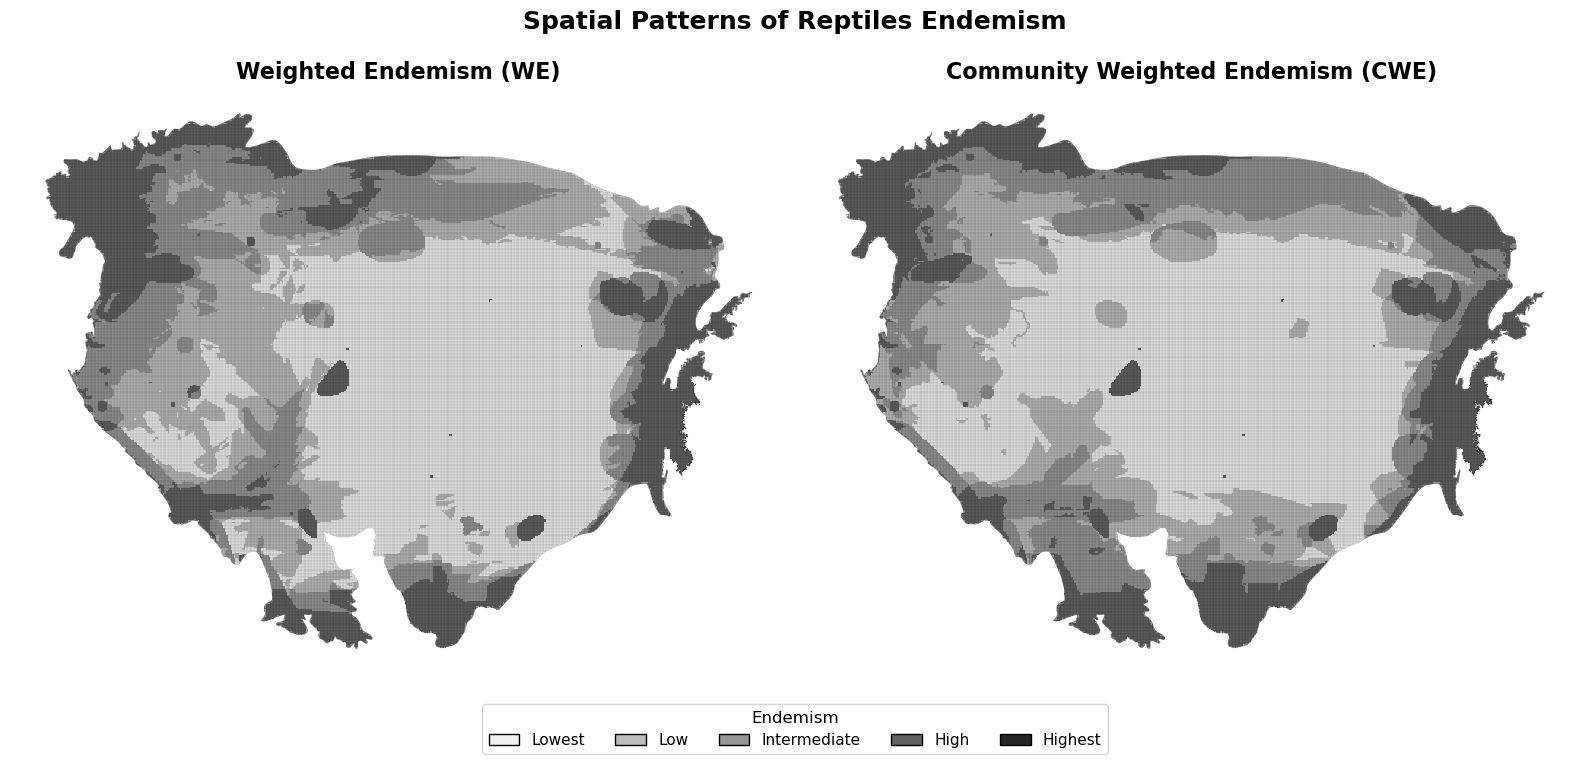

In [26]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# ---------------------------------------------------------
# 1. Define the five endemism categories
# ---------------------------------------------------------

labels = [
    "Lowest",
    "Low",
    "Intermediate",
    "High",
    "Highest"
]

# ---------------------------------------------------------
# 2. Classify WE and CWE using quintiles
# ---------------------------------------------------------

grid_reptile_biodiversity["WE_class"] = pd.qcut(
    grid_reptile_biodiversity["WE"],
    q=5,
    labels=labels,
    duplicates="drop"
)

grid_reptile_biodiversity["CWE_class"] = pd.qcut(
    grid_reptile_biodiversity["CWE"],
    q=5,
    labels=labels,
    duplicates="drop"
)

# ---------------------------------------------------------
# 3. Convert categories to numeric values
# ---------------------------------------------------------

class_values = {
    "Lowest": 1,
    "Low": 2,
    "Intermediate": 3,
    "High": 4,
    "Highest": 5
}

grid_reptile_biodiversity["WE_class_num"] = grid_reptile_biodiversity["WE_class"].map(class_values)
grid_reptile_biodiversity["CWE_class_num"] = grid_reptile_biodiversity["CWE_class"].map(class_values)

# ---------------------------------------------------------
# 4. Create figure
# ---------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 8)
)

# Five discrete colours
cmap = ListedColormap([
    "#f0f0f0",   # Lowest
    "#bdbdbd",   # Low
    "#969696",   # Intermediate
    "#636363",   # High
    "#252525"    # Highest
])

# ---------------------------------------------------------
# 5. Weighted Endemism
# ---------------------------------------------------------

grid_reptile_biodiversity.plot(
    column="WE_class_num",
    cmap=cmap,
    linewidth=0.05,
    edgecolor="black",
    ax=axes[0],
    vmin=1,
    vmax=5
)

axes[0].set_title(
    "Weighted Endemism (WE)",
    fontsize=16,
    fontweight="bold"
)

axes[0].axis("off")

# ---------------------------------------------------------
# 6. Corrected / Community Weighted Endemism
# ---------------------------------------------------------

grid_reptile_biodiversity.plot(
    column="CWE_class_num",
    cmap=cmap,
    linewidth=0.05,
    edgecolor="black",
    ax=axes[1],
    vmin=1,
    vmax=5
)

axes[1].set_title(
    "Community Weighted Endemism (CWE)",
    fontsize=16,
    fontweight="bold"
)

axes[1].axis("off")

# ---------------------------------------------------------
# 7. Common legend
# ---------------------------------------------------------

from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor=cmap(0), edgecolor="black", label="Lowest"),
    Patch(facecolor=cmap(1), edgecolor="black", label="Low"),
    Patch(facecolor=cmap(2), edgecolor="black", label="Intermediate"),
    Patch(facecolor=cmap(3), edgecolor="black", label="High"),
    Patch(facecolor=cmap(4), edgecolor="black", label="Highest")
]

fig.legend(
    handles=legend_elements,
    title="Endemism",
    loc="lower center",
    ncol=5,
    fontsize=11,
    title_fontsize=12,
    frameon=True,
    bbox_to_anchor=(0.5, 0.02)
)

# ---------------------------------------------------------
# 8. Overall figure
# ---------------------------------------------------------

plt.suptitle(
    "Spatial Patterns of Reptiles Endemism",
    fontsize=18,
    fontweight="bold",
    y=0.96
)

plt.tight_layout(rect=[0, 0.10, 1, 0.94])

# Save
plt.savefig(
    "reptiles_endemism_WE_CWE.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()